<a href="https://colab.research.google.com/github/Napoleon442/Machine-Learning-Exercise-3-/blob/main/Exercise3(Part_A).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder

   age      gender            occupation_type    chronotype  \
0   29      Female  Healthcare / Shift Worker  Intermediate   
1   58      Female                    Student  Intermediate   
2   41      Female  Healthcare / Shift Worker     Night Owl   
3   36  Non-Binary                Remote Tech  Intermediate   
4   23      Female  Healthcare / Shift Worker  Intermediate   

   bedtime_phone_minutes primary_bedtime_app  screen_brightness_pct  \
0                    179  Instagram / Reddit                     54   
1                    163             YouTube                     76   
2                    100      TikTok / Reels                     59   
3                     34             YouTube                     52   
4                     27      TikTok / Reels                     82   

   blue_light_filter_active  caffeine_post_5pm_mg  physical_activity_min  \
0                         1                     0                     21   
1                         1               

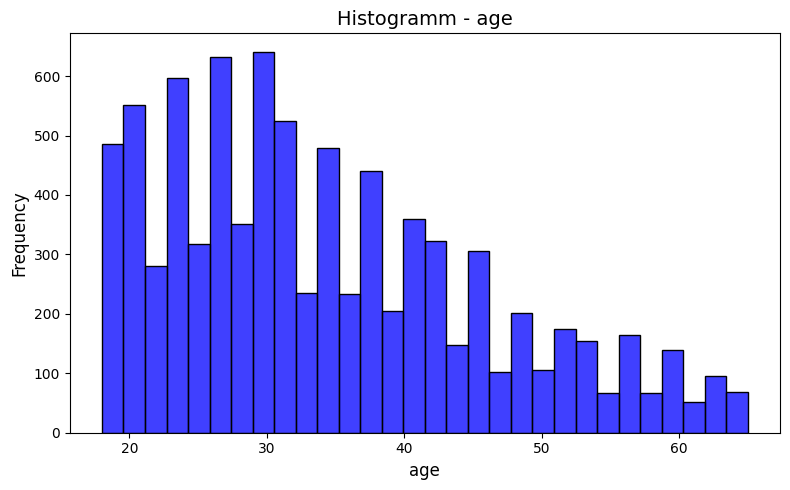

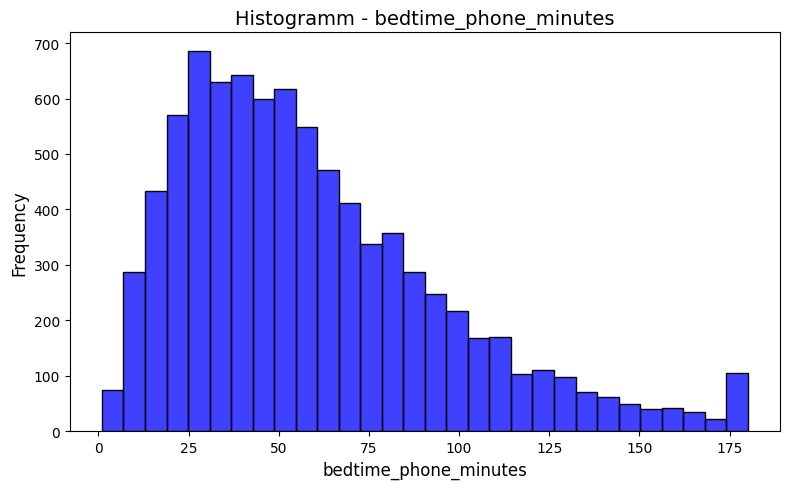

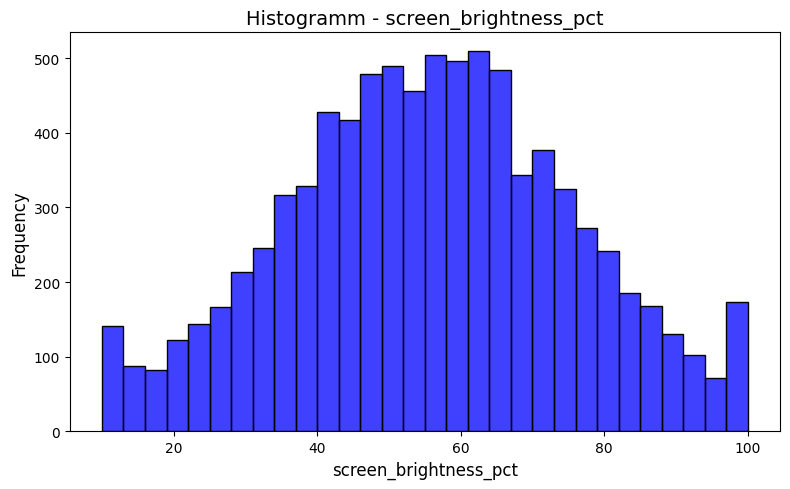

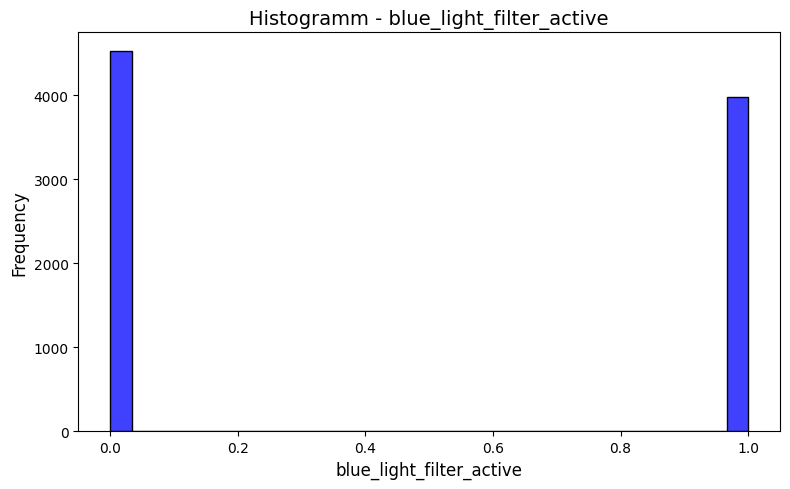

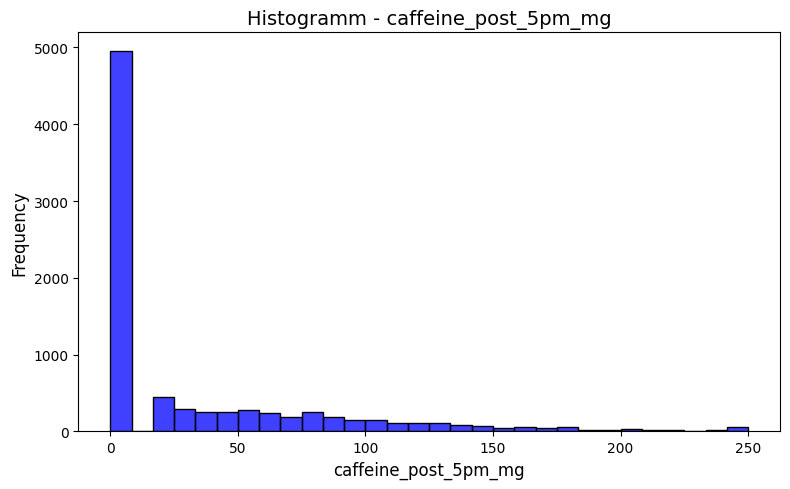

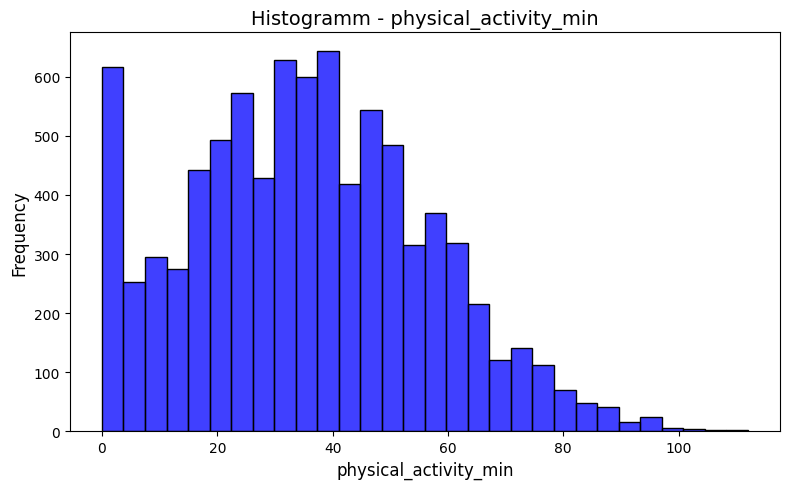

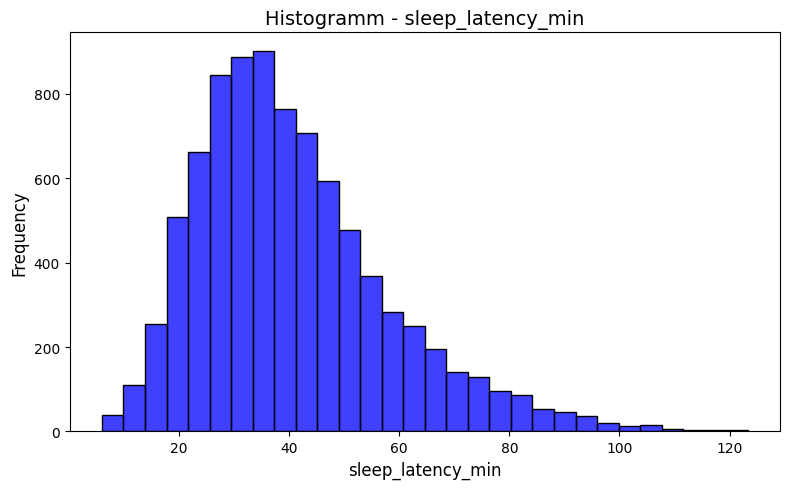

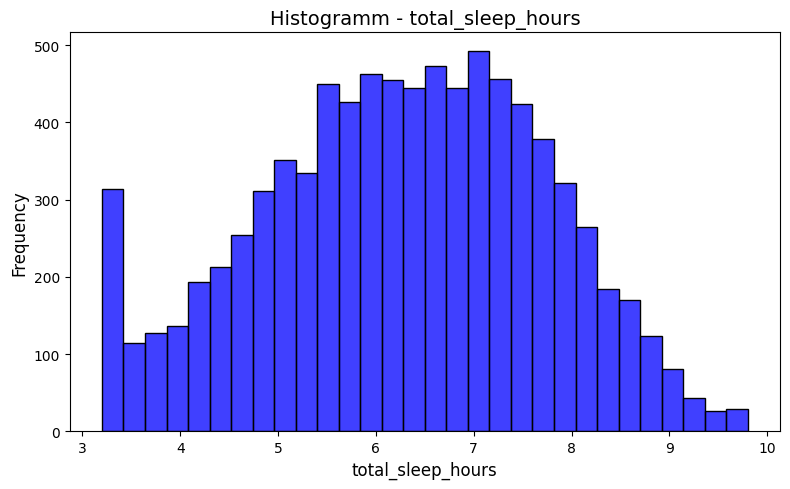

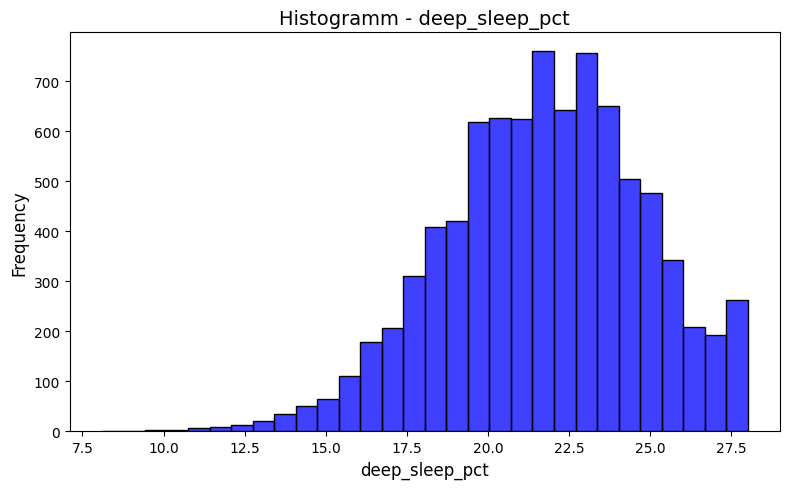

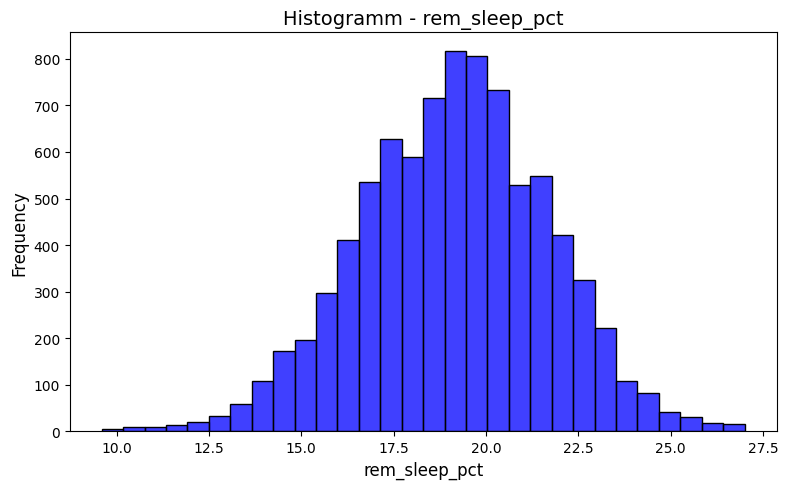

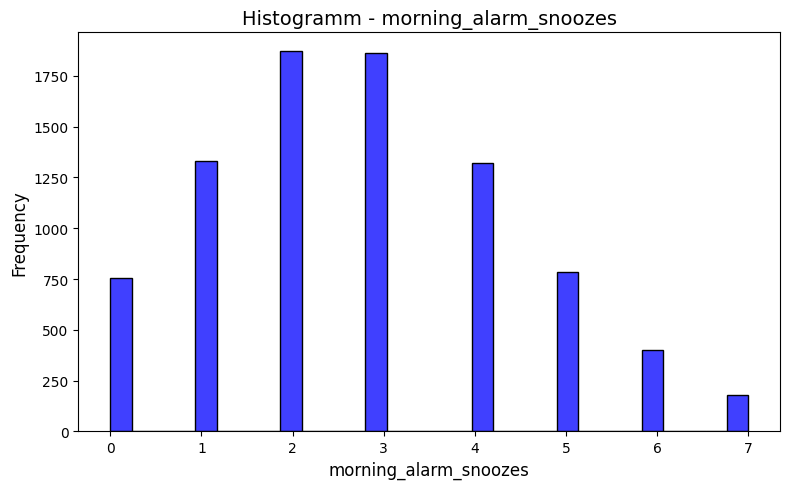

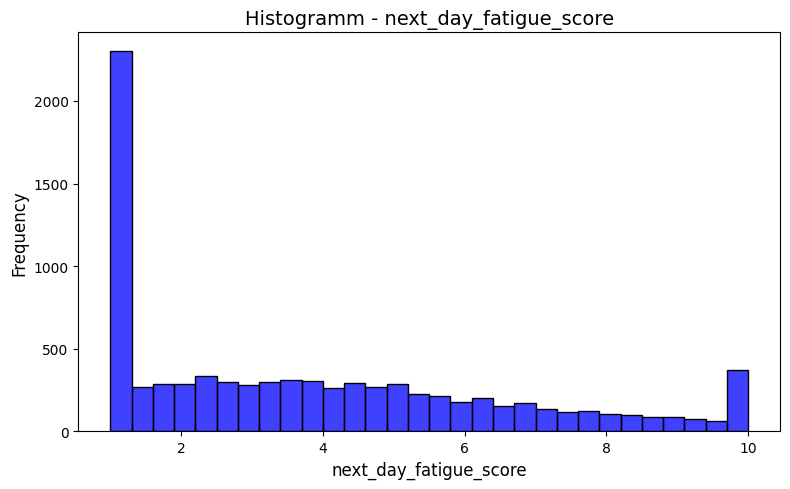

/tmp/ipykernel_3715/2938916292.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


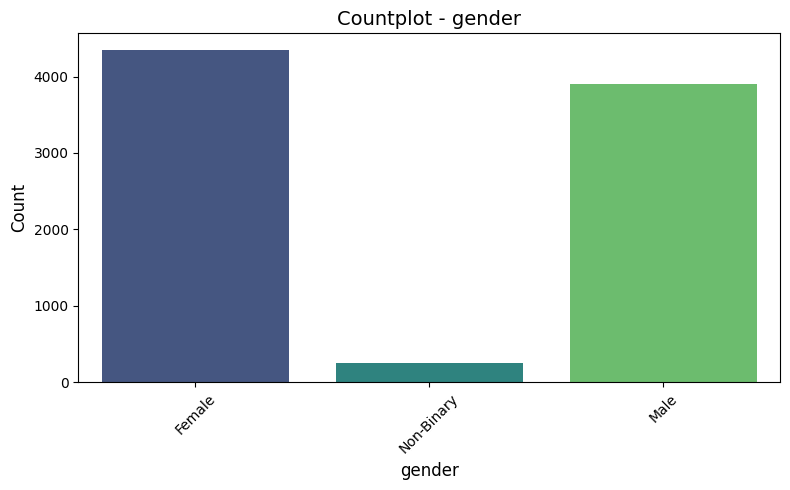

/tmp/ipykernel_3715/2938916292.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


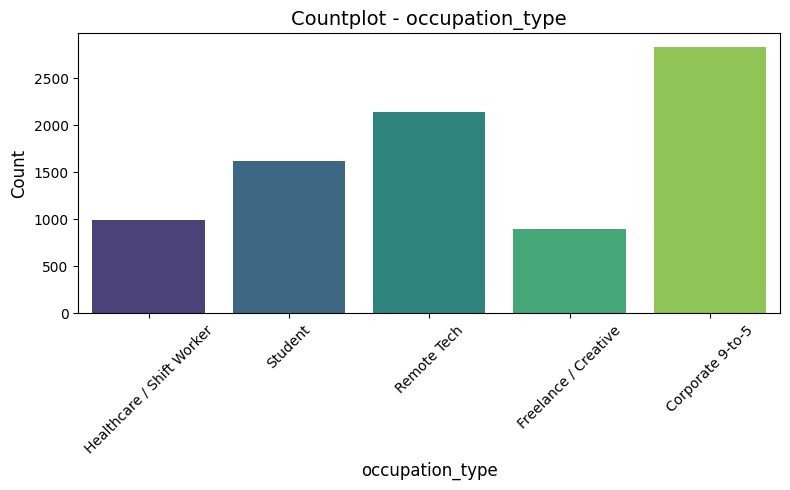

/tmp/ipykernel_3715/2938916292.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


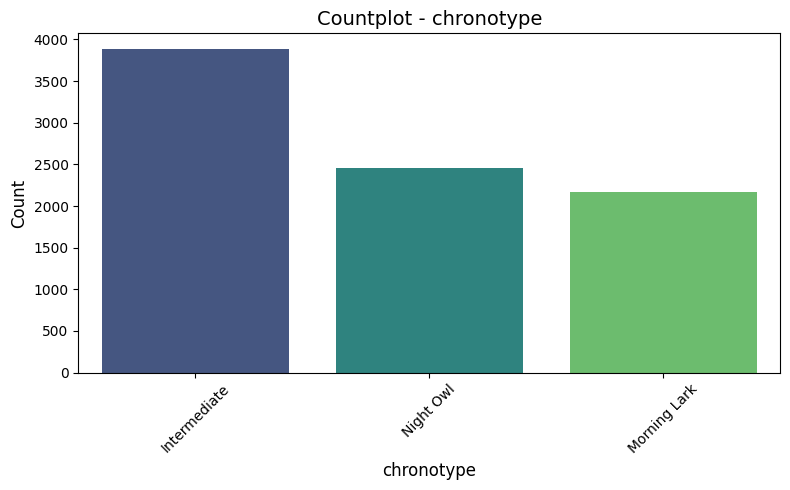

/tmp/ipykernel_3715/2938916292.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


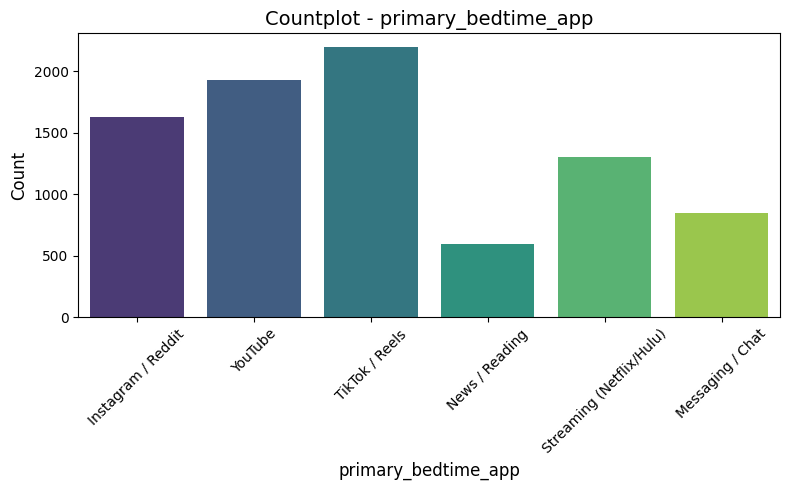

/tmp/ipykernel_3715/2938916292.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='viridis')


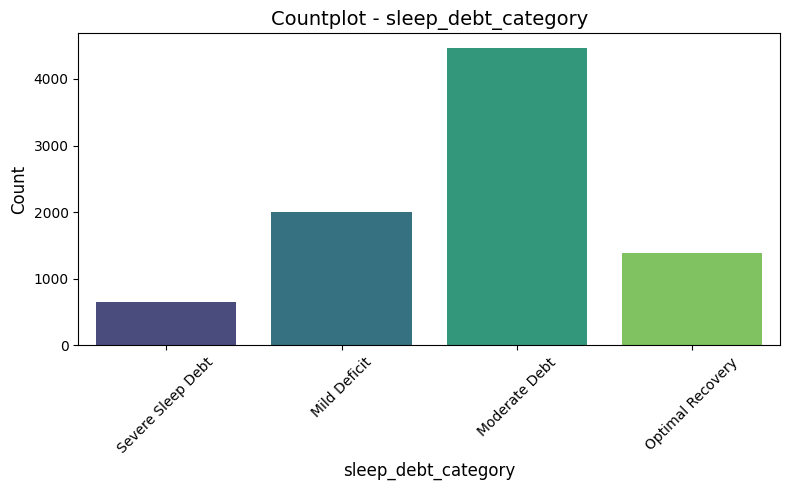

In [ ]:
#1
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

df = pd.read_csv("sleep.csv")

df= df.drop(columns=["user_id"])
print(df.head())

numerical_cols = df.select_dtypes(include=np.number).columns
print(numerical_cols)
categorical_cols = df.select_dtypes(exclude=np.number).columns
print(categorical_cols)

for col in numerical_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=col, bins=30, color='blue')
    plt.title(f"Histogramm - {col}", fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Frequency', fontsize=12)
    plt.tight_layout()
    plt.show()

for col in categorical_cols:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=col, palette='viridis')
    plt.title(f"Countplot - {col}", fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

#1
Παρατηρώντας το ραβδόγραμμα της μεταβλητής-στόχου (sleep_debt_category), καθίσταται σαφές ότι πρόκειται για πρόβλημα μη ισορροπημένων κλάσεων (imbalanced dataset). Η πλειοψηφία των δειγμάτων ανήκει στη κατηγορία Moderate Debt, ενώ η κατηγορία Severe Sleep Debt υποεκπροσωπείται έντονα.

In [ ]:
#2
df = df.drop(columns = "next_day_fatigue_score")


In [ ]:
#3
df_encoded = pd.get_dummies(df, columns=["primary_bedtime_app", "chronotype", "occupation_type", "gender"], dtype=int)
print(df_encoded.head())

sleep_debt_mapping = {"Optimal Recovery": 0, "Mild Deficit": 1, "Moderate Debt": 2, "Severe Sleep Debt": 3}
y_series = df["sleep_debt_category"].map(sleep_debt_mapping)


   age  bedtime_phone_minutes  screen_brightness_pct  \
0   29                    179                     54   
1   58                    163                     76   
2   41                    100                     59   
3   36                     34                     52   
4   23                     27                     82   

   blue_light_filter_active  caffeine_post_5pm_mg  physical_activity_min  \
0                         1                     0                     21   
1                         1                    92                     72   
2                         0                    45                     23   
3                         0                    97                     49   
4                         1                     0                     38   

   sleep_latency_min  total_sleep_hours  deep_sleep_pct  rem_sleep_pct  \
0               84.4               3.20            23.5           22.2   
1               86.7               4.06            18.0   

In [ ]:
#4

X = df_encoded.drop(columns=["sleep_debt_category"]).values
y = y_series.values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=1/3, random_state=0, stratify=y_temp)

print(f"Συνολικά δείγματα: {X.shape[0]}")
print(f"Train set (70%): {X_train.shape[0]} δείγματα")
print(f"Validation set (20%): {X_val.shape[0]} δείγματα")
print(f"Test set (10%): {X_test.shape[0]} δείγματα")


Συνολικά δείγματα: 8500
Train set (70%): 5950 δείγματα
Validation set (20%): 1700 δείγματα
Test set (10%): 850 δείγματα


In [ ]:
#5
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, balanced_accuracy_score)
import math
n = X.shape[0]
k_sqrt = int(math.sqrt(n))
if k_sqrt % 2 == 0:
    k_sqrt += 1

print(k_sqrt)

num_count = len(numerical_cols)
scaler = StandardScaler()
X_train[:, :num_count] = scaler.fit_transform(X_train[:, :num_count])
X_val[:, :num_count] = scaler.transform(X_val[:, :num_count])
X_test[:, :num_count] = scaler.transform(X_test[:, :num_count])
results = []

weight_options = ["uniform", "distance"]
k_values = [3, 5, 15, 50, 93]

for weight in weight_options:
  for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, weights=weight, metric='euclidean')
    knn.fit(X_train, y_train)
    y_val_pred = knn.predict(X_val)
    y_train_pred = knn.predict(X_train)
    results.append({
            'Weights': weight,
            'K': k,
            'Train Acc': accuracy_score(y_train, y_train_pred),
            'Val Acc': accuracy_score(y_val, y_val_pred),
            'Train Prec': precision_score(y_train, y_train_pred, average='weighted', zero_division=0),
            'Val Prec': precision_score(y_val, y_val_pred, average='weighted', zero_division=0),
            'Train Recall': recall_score(y_train, y_train_pred, average='weighted'),
            'Val Recall': recall_score(y_val, y_val_pred, average='weighted'),
            'Train F1': f1_score(y_train, y_train_pred, average='weighted'),
            'Val F1': f1_score(y_val, y_val_pred, average='weighted'),
            'Train Bal_Acc': balanced_accuracy_score(y_train, y_train_pred),
            'Val Bal_Acc': balanced_accuracy_score(y_val, y_val_pred)
    })

df_results = pd.DataFrame(results).round(3)
print(df_results)

93
    Weights   K  Train Acc  Val Acc  Train Prec  Val Prec  Train Recall  \
0   uniform   3      0.877    0.748       0.877     0.747         0.877   
1   uniform   5      0.856    0.767       0.857     0.768         0.856   
2   uniform  15      0.838    0.787       0.842     0.791         0.838   
3   uniform  50      0.811    0.794       0.820     0.801         0.811   
4   uniform  93      0.800    0.791       0.810     0.798         0.800   
5  distance   3      1.000    0.751       1.000     0.750         1.000   
6  distance   5      1.000    0.758       1.000     0.758         1.000   
7  distance  15      1.000    0.785       1.000     0.790         1.000   
8  distance  50      1.000    0.795       1.000     0.804         1.000   
9  distance  93      1.000    0.789       1.000     0.797         1.000   

   Val Recall  Train F1  Val F1  Train Bal_Acc  Val Bal_Acc  
0       0.748     0.876   0.746          0.838        0.683  
1       0.767     0.855   0.766          0.807 

In [ ]:
#6
X_train_val = np.vstack((X_train, X_val))
y_train_val = np.concatenate((y_train, y_val))

num_count = len(numerical_cols)
scaler = StandardScaler()
X_train_val[:, :num_count] = scaler.fit_transform(X_train_val[:, :num_count])
best_k = 50
best_weight = "distance"
knn_best = KNeighborsClassifier(n_neighbors=best_k, weights=best_weight, metric="euclidean")
knn_best.fit(X_train_val, y_train_val)
y_test_pred = knn_best.predict(X_test)
y_train_val_test= knn_best.predict(X_train_val)
test_results = {
    'Test Acc': accuracy_score(y_test, y_test_pred),
    'Test Prec': precision_score(y_test, y_test_pred, average='weighted', zero_division=0),
    'Test Recall': recall_score(y_test, y_test_pred, average='weighted'),
    'Test F1': f1_score(y_test, y_test_pred, average='weighted'),
    'Test Bal_Acc': balanced_accuracy_score(y_test, y_test_pred)
}

df_test_results = pd.DataFrame([test_results]).round(3)
print(df_test_results)



   Test Acc  Test Prec  Test Recall  Test F1  Test Bal_Acc
0     0.806      0.811        0.806      0.8         0.708


#6
Στη φάση της εκπαίδευσης, το μοντέλο σημείωσε απόλυτη επιτυχία (Train Acc = 1.000, Train F1 = 1.000, Train Bal_Acc = 1.000). Αυτό δεν αποτελεί υπερπροσαρμογή (overfitting) αλλά φυσιολογική ιδιότητα της παραμέτρου weights='distance', καθώς τα σημεία εκπαίδευσης έχουν μηδενική απόσταση από τον εαυτό τους. Στο Validation, το οποίο το μοντέλο δεν είχε δει κατά την εκπαίδευση, η ακρίβεια (Val Acc) διαμορφώθηκε στο 0.795 και το Val F1 στο 0.788. Αυτή η πτώση από το 1.000 ήταν αναμενόμενη και έδειξε την πραγματική, πολύ ικανοποιητική ικανότητα γενίκευσης του αλγορίθμου στα νέα δεδομένα. Στο τελικό, εντελώς άγνωστο Test Set, αφού το μοντέλο εκπαιδεύτηκε πλέον σε περισσότερα δεδομένα (ενωμένο Train + Validation), η ακρίβεια βελτιώθηκε ελαφρώς, φτάνοντας στο 0.806. Το γεγονός ότι το Test Acc (0.806) είναι ελαφρώς υψηλότερο από το Val Acc (0.795) αποδεικνύει ότι η ενσωμάτωση του Validation set στην τελική εκπαίδευση βοήθησε τον αλγόριθμο να μάθει ακόμα καλύτερα το χώρο, οδηγώντας σε ένα εξαιρετικά σταθερό μοντέλο που δεν κάνει overfitting.   

In [ ]:
#7
import scipy.stats as st
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import make_scorer

df = pd.read_csv("sleep.csv")
df = df.drop(columns=["user_id", "next_day_fatigue_score"])

target_col = "sleep_debt_category"
categorical_cols = ["primary_bedtime_app", "chronotype", "occupation_type", "gender"]
numerical_cols = df.drop(columns=[target_col]).select_dtypes(include=np.number).columns.tolist()

y_mapping = {"Optimal Recovery": 0, "Mild Deficit": 1, "Moderate Debt": 2, "Severe Sleep Debt": 3}
y = df[target_col].map(y_mapping).values

X_df = df.drop(columns=[target_col])
X = pd.get_dummies(X_df, columns=categorical_cols, dtype=int).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=0, stratify=y)

num_count = len(numerical_cols)
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), list(range(num_count)))],
    remainder='passthrough'
)

scoring = {
    'Acc': make_scorer(accuracy_score),
    'Prec': make_scorer(precision_score, average='weighted', zero_division=0),
    'Rec': make_scorer(recall_score, average='weighted'),
    'F1': make_scorer(f1_score, average='weighted'),
    'Bal_Acc': make_scorer(balanced_accuracy_score)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results = []
cv_scores_dict = {}
k_values = [3, 5, 15, 50, 93]
weights_options = ['uniform', 'distance']

for w in weights_options:
    for k in k_values:

        knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean')
        pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('knn', knn)])

        scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)

        results.append({
            'Weights': w, 'K': k,
            'Mean Acc': np.mean(scores['test_Acc']),
            'Mean Prec': np.mean(scores['test_Prec']),
            'Mean Recall': np.mean(scores['test_Rec']),
            'Mean F1': np.mean(scores['test_F1']),
            'Mean Bal_Acc': np.mean(scores['test_Bal_Acc'])
        })
        cv_scores_dict[f"{w}_{k}"] = scores

df_results = pd.DataFrame(results).sort_values(by='Mean Acc', ascending=False)
print("--- Τα 5 Καλύτερα Μοντέλα βάσει CV ---")
print(df_results.head().round(3))

best_model_key = f"{df_results.iloc[0]['Weights']}_{df_results.iloc[0]['K']}"
print(f"\n--- Διαστήματα Εμπιστοσύνης (95%) για το: {best_model_key} ---")

best_scores = cv_scores_dict[best_model_key]
for metric_name in scoring.keys():
    fold_scores = best_scores[f'test_{metric_name}']
    mean_score = np.mean(fold_scores)

    ci = st.t.interval(0.95, df=len(fold_scores)-1, loc=mean_score, scale=st.sem(fold_scores))
    print(f"{metric_name:7s}: Mean = {mean_score:.3f}, 95% CI = ({ci[0]:.3f} - {ci[1]:.3f})")

--- Τα 5 Καλύτερα Μοντέλα βάσει CV ---
    Weights   K  Mean Acc  Mean Prec  Mean Recall  Mean F1  Mean Bal_Acc
8  distance  50     0.808      0.815        0.808    0.802         0.709
2   uniform  15     0.807      0.810        0.807    0.805         0.734
7  distance  15     0.807      0.810        0.807    0.804         0.730
3   uniform  50     0.806      0.813        0.806    0.800         0.703
4   uniform  93     0.796      0.807        0.796    0.788         0.677

--- Διαστήματα Εμπιστοσύνης (95%) για το: distance_50 ---
Acc    : Mean = 0.808, 95% CI = (0.802 - 0.813)
Prec   : Mean = 0.815, 95% CI = (0.807 - 0.822)
Rec    : Mean = 0.808, 95% CI = (0.802 - 0.813)
F1     : Mean = 0.802, 95% CI = (0.797 - 0.808)
Bal_Acc: Mean = 0.709, 95% CI = (0.701 - 0.717)


In [ ]:
#8
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score

df = pd.read_csv("sleep.csv")
df = df.drop(columns=["user_id", "next_day_fatigue_score"])

target_col = "sleep_debt_category"
categorical_cols = ["primary_bedtime_app", "chronotype", "occupation_type", "gender"]
numerical_cols = df.drop(columns=[target_col]).select_dtypes(include=np.number).columns.tolist()

y_mapping = {"Optimal Recovery": 0, "Mild Deficit": 1, "Moderate Debt": 2, "Severe Sleep Debt": 3}
y = df[target_col].map(y_mapping).values

X_df = df.drop(columns=[target_col])
X = pd.get_dummies(X_df, columns=categorical_cols, dtype=int).values

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)

num_count = len(numerical_cols)
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), list(range(num_count)))],
    remainder='passthrough'
)
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('knn', KNeighborsClassifier(metric='euclidean'))])

param_grid = {
    'knn__n_neighbors': [3, 5, 15, 50, 93],
    'knn__weights': ['uniform', 'distance']
}

grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1)

scoring = {
    'Acc': make_scorer(accuracy_score),
    'Prec': make_scorer(precision_score, average='weighted', zero_division=0),
    'Rec': make_scorer(recall_score, average='weighted'),
    'F1': make_scorer(f1_score, average='weighted'),
    'Bal_Acc': make_scorer(balanced_accuracy_score)
}

outer_results = cross_validate(grid_search, X, y, cv=outer_cv, scoring=scoring, return_estimator=True)

print("\n--- Μέσες Μετρικές από το Outer CV (3 Folds) ---")
print(f"Accuracy : {np.mean(outer_results['test_Acc']):.3f} (± {np.std(outer_results['test_Acc']):.3f})")
print(f"Precision: {np.mean(outer_results['test_Prec']):.3f} (± {np.std(outer_results['test_Prec']):.3f})")
print(f"Recall   : {np.mean(outer_results['test_Rec']):.3f} (± {np.std(outer_results['test_Rec']):.3f})")
print(f"F1-Score : {np.mean(outer_results['test_F1']):.3f} (± {np.std(outer_results['test_F1']):.3f})")
print(f"Bal. Acc : {np.mean(outer_results['test_Bal_Acc']):.3f} (± {np.std(outer_results['test_Bal_Acc']):.3f})")

print("\n--- Παράμετροι που επιλέχθηκαν ανά Outer Fold ---")
for i, estimator in enumerate(outer_results['estimator']):
    best_params = estimator.best_params_
    k = best_params['knn__n_neighbors']
    w = best_params['knn__weights']
    print(f"Fold {i+1}: k={k}, weights='{w}'")

Εκκίνηση Nested CV... (Μπορεί να πάρει λίγο χρόνο)

--- Μέσες Μετρικές από το Outer CV (3 Folds) ---
Accuracy : 0.806 (± 0.003)
Precision: 0.813 (± 0.005)
Recall   : 0.806 (± 0.003)
F1-Score : 0.802 (± 0.003)
Bal. Acc : 0.714 (± 0.012)

--- Παράμετροι που επιλέχθηκαν ανά Outer Fold ---
Fold 1: k=15, weights='distance'
Fold 2: k=50, weights='distance'
Fold 3: k=50, weights='uniform'
